<a href="https://colab.research.google.com/github/PanwarParth1/AI-ML-Learning/blob/main/Titanic_survival_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
from google.colab import files
a = files.upload()
a

Saving test.csv to test.csv
Saving train.csv to train.csv


{'test.csv': b'PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked\r\n892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,,Q\r\n893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47,1,0,363272,7,,S\r\n894,2,"Myles, Mr. Thomas Francis",male,62,0,0,240276,9.6875,,Q\r\n895,3,"Wirz, Mr. Albert",male,27,0,0,315154,8.6625,,S\r\n896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22,1,1,3101298,12.2875,,S\r\n897,3,"Svensson, Mr. Johan Cervin",male,14,0,0,7538,9.225,,S\r\n898,3,"Connolly, Miss. Kate",female,30,0,0,330972,7.6292,,Q\r\n899,2,"Caldwell, Mr. Albert Francis",male,26,1,1,248738,29,,S\r\n900,3,"Abrahim, Mrs. Joseph (Sophie Halaut Easu)",female,18,0,0,2657,7.2292,,C\r\n901,3,"Davies, Mr. John Samuel",male,21,2,0,A/4 48871,24.15,,S\r\n902,3,"Ilieff, Mr. Ylio",male,,0,0,349220,7.8958,,S\r\n903,1,"Jones, Mr. Charles Cresson",male,46,0,0,694,26,,S\r\n904,1,"Snyder, Mrs. John Pillsbury (Nelle Stevenson)",female,23,1,0,21228,82.2667,B45,S\r\n905,2,"Howard, Mr. Benja

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [6]:
Titanic_data = pd.read_csv("train.csv")
Titanic_data

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [7]:
Titanic_data.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


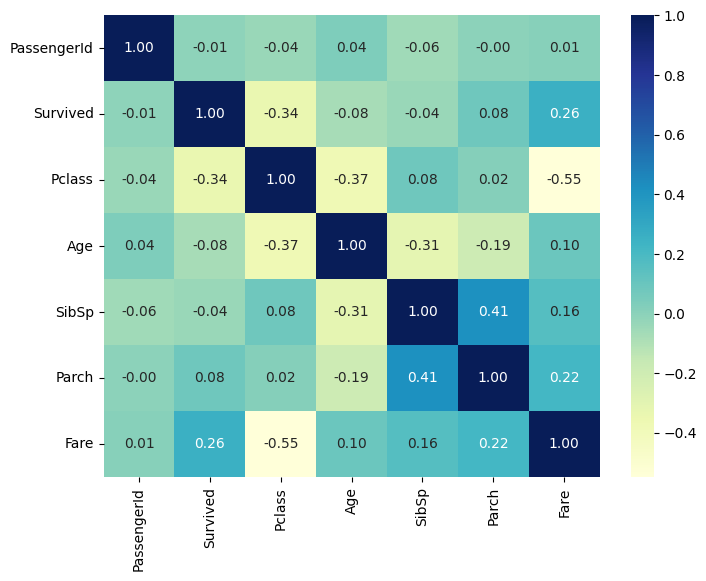

In [8]:
import seaborn as sns
plt.figure(figsize=(8, 6))
sns.heatmap(Titanic_data.select_dtypes(include=[np.number]).corr(), annot=True, cmap='YlGnBu', fmt='.2f')
plt.show()

In [9]:
from sklearn.model_selection import StratifiedShuffleSplit
split =StratifiedShuffleSplit(n_splits=1 , test_size = 0.2 , random_state=42)
for train_indices , test_indices in split.split(Titanic_data , Titanic_data[["Survived" , "Pclass","Sex"]]):
  strat_trian_set = Titanic_data.iloc[train_indices]
  strat_test_set = Titanic_data.iloc[test_indices]

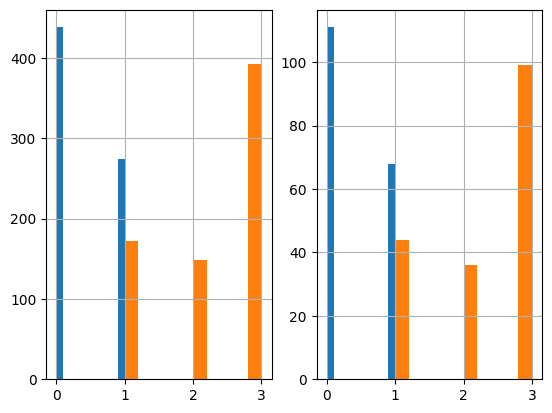

In [10]:
plt.subplot(1,2,1)
strat_trian_set["Survived"].hist()
strat_trian_set["Pclass"].hist()

plt.subplot(1,2,2)
strat_test_set["Survived"].hist()
strat_test_set["Pclass"].hist()
plt.show()


In [11]:
strat_trian_set.info()

<class 'pandas.core.frame.DataFrame'>
Index: 712 entries, 867 to 802
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  712 non-null    int64  
 1   Survived     712 non-null    int64  
 2   Pclass       712 non-null    int64  
 3   Name         712 non-null    object 
 4   Sex          712 non-null    object 
 5   Age          565 non-null    float64
 6   SibSp        712 non-null    int64  
 7   Parch        712 non-null    int64  
 8   Ticket       712 non-null    object 
 9   Fare         712 non-null    float64
 10  Cabin        167 non-null    object 
 11  Embarked     710 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 72.3+ KB


In [20]:
from sklearn.base import BaseEstimator , TransformerMixin
from sklearn.impute import SimpleImputer

class AgeImputer(BaseEstimator , TransformerMixin):
  def fit(self , X , y=None):
    return self

  def transform(self, X):
    imputer = SimpleImputer(strategy="median")
    X.loc[:, "Age"] = imputer.fit_transform(X[["Age"]])
    return X

In [29]:
from sklearn.preprocessing import OneHotEncoder

class FeatureEncoder(BaseEstimator , TransformerMixin):
  def fit(self , X , y=None):
    return self

  def transform(self, X):
        encoder = OneHotEncoder()
        matrix = encoder.fit_transform(X[['Sex']]).toarray()

        # Curly braces {} ki jagah square brackets [] use karein taaki ye list bane
        column_names = ["Female", "Male"]

        for i in range(len(matrix.T)):
            X.loc[:, column_names[i]] = matrix.T[i]

        return X

In [30]:
class FeatureDropper(BaseEstimator, TransformerMixin):
  def fit(self , X , y= None):
    return self
  def transform(self, X):
    return X.drop(["Embarked" , "Name" , "Ticket" ,"Cabin", "Sex" , "N"] , axis = 1 , errors="ignore")


In [31]:
from sklearn.pipeline import Pipeline
pipeline = Pipeline([("ageimputer" , AgeImputer()),
                     ("Featureencoder" , FeatureEncoder()),
                     ("FeatureDecoder" , FeatureDropper())])


In [32]:
strat_trian_set = pipeline.fit_transform(strat_trian_set)


/tmp/ipykernel_5028/3085308740.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X.loc[:, column_names[i]] = matrix.T[i]
/tmp/ipykernel_5028/3085308740.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X.loc[:, column_names[i]] = matrix.T[i]


In [34]:
strat_trian_set

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare,C,S,Q,Female,Male
867,868,0,1,31.0,0,0,50.4958,0.0,0.0,1.0,0.0,1.0
619,620,0,2,26.0,0,0,10.5000,0.0,0.0,1.0,0.0,1.0
50,51,0,3,7.0,4,1,39.6875,0.0,0.0,1.0,0.0,1.0
286,287,1,3,30.0,0,0,9.5000,0.0,0.0,1.0,0.0,1.0
834,835,0,3,18.0,0,0,8.3000,0.0,0.0,1.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...
482,483,0,3,50.0,0,0,8.0500,0.0,0.0,1.0,0.0,1.0
518,519,1,2,36.0,1,0,26.0000,0.0,0.0,1.0,1.0,0.0
54,55,0,1,65.0,0,1,61.9792,1.0,0.0,0.0,0.0,1.0
603,604,0,3,44.0,0,0,8.0500,0.0,0.0,1.0,0.0,1.0


In [36]:
strat_trian_set.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Age,0
SibSp,0
Parch,0
Fare,0
C,0
S,0
Q,0


In [39]:
from sklearn.preprocessing import StandardScaler
X = strat_trian_set.drop("Survived" , axis = 1)
y = strat_trian_set["Survived"]
scalar = StandardScaler()
X_data = scalar.fit_transform(X)
Y_data = y.to_numpy()

In [40]:
X_data

array([[ 1.6422641 , -1.56828591,  0.12354285, ...,  0.61197825,
        -0.73561236,  0.73561236],
       [ 0.67661178, -0.37019624, -0.26296623, ...,  0.61197825,
        -0.73561236,  0.73561236],
       [-1.53893728,  0.82789342, -1.73170073, ...,  0.61197825,
        -0.73561236,  0.73561236],
       ...,
       [-1.52336225, -1.56828591,  2.75180459, ..., -1.63404501,
        -0.73561236,  0.73561236],
       [ 0.61431163,  0.82789342,  1.12846645, ...,  0.61197825,
        -0.73561236,  0.73561236],
       [ 1.38916974, -1.56828591, -1.42249347, ...,  0.61197825,
        -0.73561236,  0.73561236]])